# Семинар №4. Кривые второго порядка, преобразования и поверхности
## Подготовка к лабораторной работе №4

**Цель:** связать математическую формулу с геометрией и с тем, как эта геометрия будет строиться в Python.

На семинаре:

- эллипс, гипербола, парабола;
- параметрическая и неявная формы;
- общее уравнение $Ax^2+Bxy+Cy^2+Dx+Ey+F=0$;
- дискриминант $B^2-4AC$;
- перенос, масштабирование и поворот;
- однородные координаты;
- порядок преобразований;
- `meshgrid`;
- эллипсоид, однополостный гиперболоид, эллиптический параболоид;
- линии уровня и связь `contour` с 3D-поверхностью.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 12

try:
    from ipywidgets import interact, FloatSlider, IntSlider, Dropdown
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print("Интерактивные виджеты недоступны. Статические графики продолжат работать.")

Интерактивные виджеты недоступны. Статические графики продолжат работать.


# 1. Канонические кривые второго порядка

## Эллипс

$$
\frac{x^2}{a^2}+\frac{y^2}{b^2}=1
$$

Параметризация:

$$
x=a\cos t,\qquad y=b\sin t,\qquad t\in[0,2\pi].
$$

## Гипербола

$$
\frac{x^2}{a^2}-\frac{y^2}{b^2}=1
$$

Правая ветвь:

$$
x=a\cosh t,\qquad y=b\sinh t.
$$

Левая ветвь получается заменой $x\to -x$.

## Парабола

$$
y^2=2px.
$$

Параметризация:

$$
x=\frac{t^2}{2p},\qquad y=t.
$$

Для $y^2=4x$ имеем $p=2$.

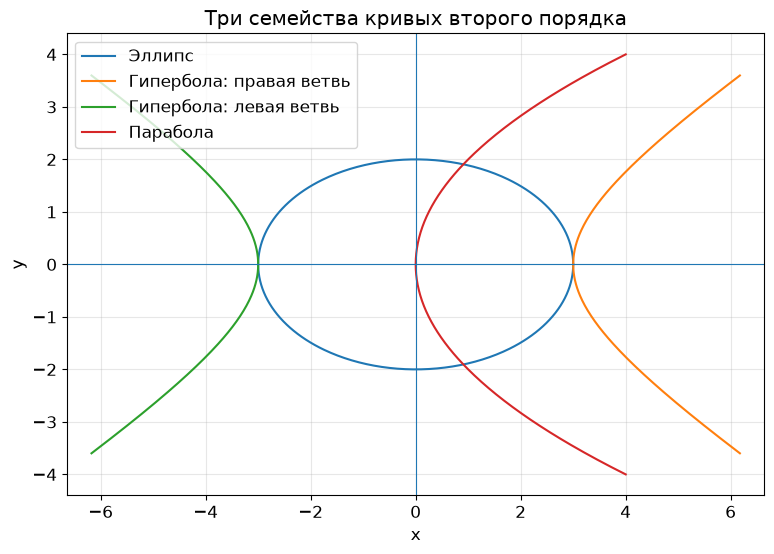

In [2]:
a, b = 3.0, 2.0

t = np.linspace(0, 2*np.pi, 500)
x_e = a*np.cos(t)
y_e = b*np.sin(t)

th = np.linspace(-1.35, 1.35, 300)
x_h = a*np.cosh(th)
y_h = b*np.sinh(th)

tp = np.linspace(-4, 4, 400)
x_p = tp**2 / 4
y_p = tp

plt.figure(figsize=(9, 6))
plt.plot(x_e, y_e, label="Эллипс")
plt.plot(x_h, y_h, label="Гипербола: правая ветвь")
plt.plot(-x_h, y_h, label="Гипербола: левая ветвь")
plt.plot(x_p, y_p, label="Парабола")
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Три семейства кривых второго порядка")
plt.legend()
plt.show()

## Что означает параметр $t$?

Параметризацию удобно воспринимать как **движение точки по кривой**.

Для эллипса:

- $t=0$ → $(a,0)$;
- $t=\pi/2$ → $(0,b)$;
- $t=\pi$ → $(-a,0)$;
- $t=2\pi$ → возврат в исходную точку.

То есть $x(t)$ и $y(t)$ задают координаты одной движущейся точки.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


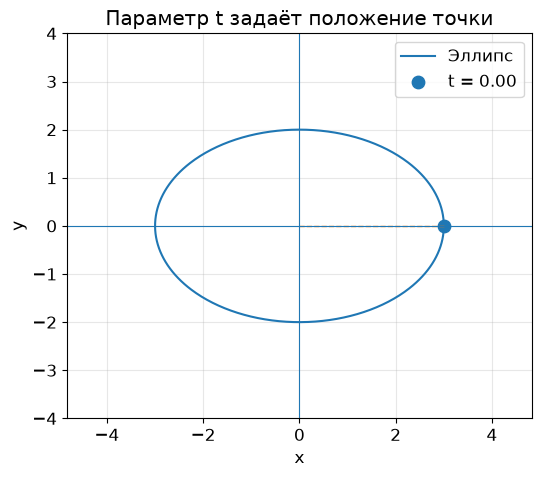

In [3]:
def show_point_on_ellipse(t=0.0, a=3.0, b=2.0):
    tt = np.linspace(0, 2*np.pi, 500)
    x = a*np.cos(tt)
    y = b*np.sin(tt)

    xp = a*np.cos(t)
    yp = b*np.sin(t)

    plt.figure(figsize=(6, 5))
    plt.plot(x, y, label="Эллипс")
    plt.scatter([xp], [yp], s=80, label=f"t = {t:.2f}")
    plt.plot([0, xp], [0, yp], linestyle="--", linewidth=1)
    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)
    plt.axis("equal")
    plt.xlim(-5, 5)
    plt.ylim(-4, 4)
    plt.grid(True, alpha=0.3)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Параметр t задаёт положение точки")
    plt.legend()
    plt.show()

if WIDGETS_AVAILABLE:
    interact(
        show_point_on_ellipse,
        t=FloatSlider(min=0, max=2*np.pi, step=0.1, value=0, description="t"),
        a=FloatSlider(min=1, max=5, step=0.25, value=3, description="a"),
        b=FloatSlider(min=0.5, max=4, step=0.25, value=2, description="b")
    );
else:
    show_point_on_ellipse()

## Задание 1

Для кривых

$$
\frac{x^2}{9}+\frac{y^2}{4}=1,
$$

$$
\frac{x^2}{9}-\frac{y^2}{4}=1,
$$

$$
y^2=4x
$$

укажите:

1. параметризацию;
2. разумный диапазон параметра для построения;
3. сколько частей/ветвей нужно построить.

<details>
<summary><b>Решение задания 1</b></summary>

### Эллипс

$$
x=3\cos t,\qquad y=2\sin t,\qquad t\in[0,2\pi].
$$

### Гипербола

Правая ветвь:

$$
x=3\cosh t,\qquad y=2\sinh t.
$$

Левая:

$$
x=-3\cosh t,\qquad y=2\sinh t.
$$

Математически $t\in\mathbb R$, но для графика берётся конечный интервал, например $[-1.5,1.5]$.

### Парабола

$$
x=\frac{t^2}{4},\qquad y=t.
$$

Например, $t\in[-4,4]$.

</details>

# 2. Общее уравнение кривой второго порядка

Общий вид:

$$
Ax^2+Bxy+Cy^2+Dx+Ey+F=0.
$$

Для невырожденной вещественной кривой рассматривают

$$
\Delta=B^2-4AC.
$$

- $\Delta<0$ — эллиптическое семейство;
- $\Delta=0$ — параболическое;
- $\Delta>0$ — гиперболическое.

При этом одного знака $\Delta$ недостаточно, чтобы исключить вырожденный случай. В вариантах ЛР №4 кривые подобраны невырожденными.

### Геометрические подсказки

- член $Bxy$ обычно появляется после **поворота**;
- линейные члены $Dx+Ey$ — после **переноса**;
- коэффициенты при $x^2$ и $y^2$ связаны с формой и масштабом.

## Пример из системы вариантов ЛР №4

Пусть канонический эллипс

$$
\frac{X^2}{9}+\frac{Y^2}{4}=1
$$

имеет центр $(-1,-2)$ и повёрнут на

$$
\theta=\frac{\pi}{4}.
$$

После замены координат и раскрытия скобок получается

$$
13x^2-10xy+13y^2+6x+42y-27=0.
$$

В общем виде исходный эллипс уже трудно распознать глазами.

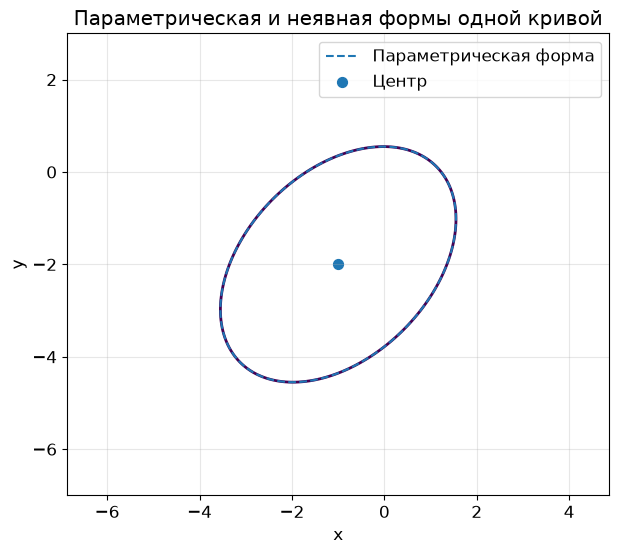

In [4]:
theta = np.pi/4
p, q = -1.0, -2.0
a, b = 3.0, 2.0

t = np.linspace(0, 2*np.pi, 600)
X_local = a*np.cos(t)
Y_local = b*np.sin(t)

x_param = p + np.cos(theta)*X_local - np.sin(theta)*Y_local
y_param = q + np.sin(theta)*X_local + np.cos(theta)*Y_local

xx = np.linspace(-6, 4, 500)
yy = np.linspace(-7, 3, 500)
XX, YY = np.meshgrid(xx, yy)

F = 13*XX**2 - 10*XX*YY + 13*YY**2 + 6*XX + 42*YY - 27

plt.figure(figsize=(7, 6))
plt.contour(XX, YY, F, levels=[0], linewidths=2)
plt.plot(x_param, y_param, linestyle="--", label="Параметрическая форма")
plt.scatter([p], [q], s=50, label="Центр")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Параметрическая и неявная формы одной кривой")
plt.legend()
plt.show()

## Задание 2

Для

$$
13x^2-10xy+13y^2+6x+42y-27=0
$$

1. выпишите $A,B,C$;
2. вычислите $\Delta$;
3. определите семейство кривой;
4. укажите член, который говорит о повороте осей.

<details>
<summary><b>Решение задания 2</b></summary>

$$
A=13,\qquad B=-10,\qquad C=13.
$$

$$
\Delta=(-10)^2-4\cdot13\cdot13
=100-676=-576<0.
$$

Кривая относится к **эллиптическому семейству**.

Слагаемое

$$
-10xy
$$

указывает на поворот главных осей относительно осей $x,y$.

</details>

# 3. Однородные координаты и преобразования

Точка записывается как

$$
p=
\begin{pmatrix}
x\\y\\1
\end{pmatrix}.
$$

## Перенос

$$
T(t_x,t_y)=
\begin{pmatrix}
1&0&t_x\\
0&1&t_y\\
0&0&1
\end{pmatrix}.
$$

## Масштабирование

$$
S(s_x,s_y)=
\begin{pmatrix}
s_x&0&0\\
0&s_y&0\\
0&0&1
\end{pmatrix}.
$$

## Поворот

$$
R(\varphi)=
\begin{pmatrix}
\cos\varphi&-\sin\varphi&0\\
\sin\varphi&\cos\varphi&0\\
0&0&1
\end{pmatrix}.
$$

Преобразование:

$$
p_{\text{new}}=Mp.
$$

In [5]:
def translation_matrix(tx, ty):
    return np.array([
        [1.0, 0.0, tx],
        [0.0, 1.0, ty],
        [0.0, 0.0, 1.0]
    ])

def scaling_matrix(sx, sy):
    return np.array([
        [sx, 0.0, 0.0],
        [0.0, sy, 0.0],
        [0.0, 0.0, 1.0]
    ])

def rotation_matrix(phi):
    c = np.cos(phi)
    s = np.sin(phi)
    return np.array([
        [c, -s, 0.0],
        [s,  c, 0.0],
        [0.0, 0.0, 1.0]
    ])

def ellipse_points(a=3.0, b=2.0, n=500):
    t = np.linspace(0, 2*np.pi, n)
    return np.vstack([
        a*np.cos(t),
        b*np.sin(t),
        np.ones_like(t)
    ])

def apply_transform(points, M):
    return M @ points

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


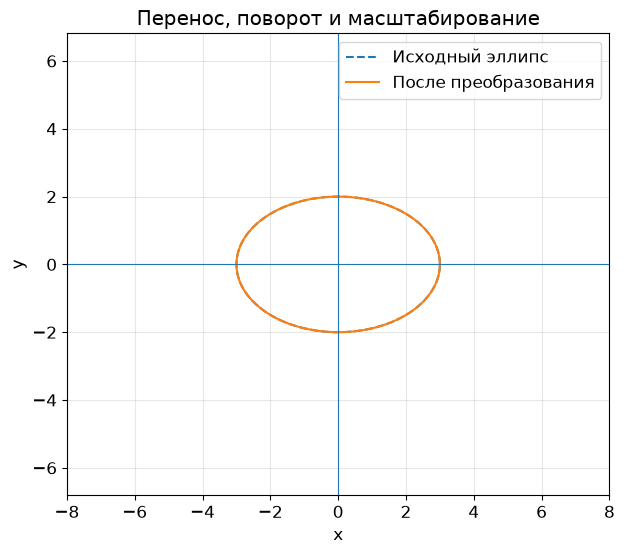

In [6]:
def interactive_transform(phi_deg=0, tx=0, ty=0, sx=1.0, sy=1.0):
    points = ellipse_points(3, 2)
    phi = np.deg2rad(phi_deg)

    # Справа действует первым:
    # масштабирование → поворот → перенос.
    M = (
        translation_matrix(tx, ty)
        @ rotation_matrix(phi)
        @ scaling_matrix(sx, sy)
    )

    transformed = apply_transform(points, M)

    plt.figure(figsize=(7, 6))
    plt.plot(points[0], points[1], linestyle="--", label="Исходный эллипс")
    plt.plot(transformed[0], transformed[1], label="После преобразования")
    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)
    plt.axis("equal")
    plt.xlim(-8, 8)
    plt.ylim(-7, 7)
    plt.grid(True, alpha=0.3)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Перенос, поворот и масштабирование")
    plt.legend()
    plt.show()

if WIDGETS_AVAILABLE:
    interact(
        interactive_transform,
        phi_deg=FloatSlider(min=-180, max=180, step=5, value=0, description="φ, °"),
        tx=FloatSlider(min=-4, max=4, step=0.25, value=0, description="tx"),
        ty=FloatSlider(min=-4, max=4, step=0.25, value=0, description="ty"),
        sx=FloatSlider(min=0.3, max=2.0, step=0.1, value=1.0, description="sx"),
        sy=FloatSlider(min=0.3, max=2.0, step=0.1, value=1.0, description="sy")
    );
else:
    interactive_transform()

## Задание 3

Точка

$$
P=
\begin{pmatrix}
1\\0\\1
\end{pmatrix}
$$

сначала поворачивается на $90^\circ$, затем переносится на $(2,1)$.

Найдите:

1. точку после поворота;
2. итоговую точку;
3. общую матрицу преобразования.

<details>
<summary><b>Решение задания 3</b></summary>

Для $\varphi=\pi/2$:

$$
R=
\begin{pmatrix}
0&-1&0\\
1&0&0\\
0&0&1
\end{pmatrix}.
$$

$$
RP=
\begin{pmatrix}
0\\1\\1
\end{pmatrix}.
$$

Перенос:

$$
T=
\begin{pmatrix}
1&0&2\\
0&1&1\\
0&0&1
\end{pmatrix}.
$$

$$
TRP=
\begin{pmatrix}
2\\2\\1
\end{pmatrix}.
$$

Общая матрица:

$$
M=TR,
$$

потому что правая матрица действует первой.

</details>

# 4. Почему порядок преобразований важен?

В общем случае

$$
TR\neq RT.
$$

Смысл:

- **сначала повернуть, потом сдвинуть**;
- **сначала сдвинуть, потом повернуть**

— разные геометрические действия, поскольку поворот выполняется вокруг начала координат.

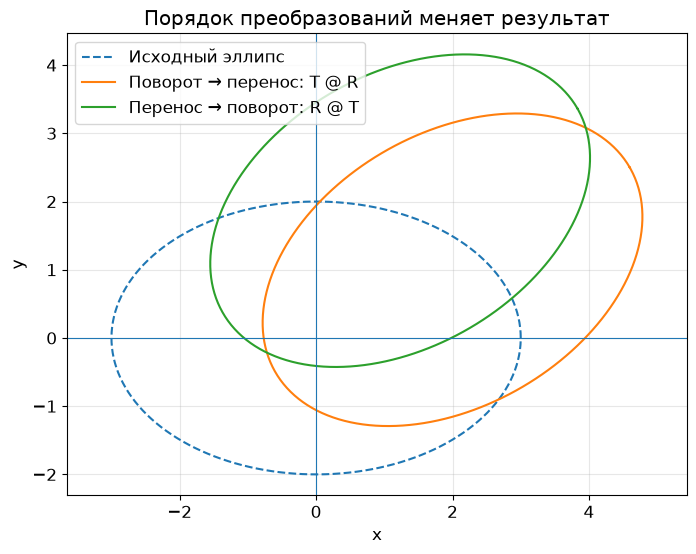

In [7]:
points = ellipse_points(3, 2)

R = rotation_matrix(np.pi/6)
T = translation_matrix(2, 1)

curve_TR = (T @ R) @ points
curve_RT = (R @ T) @ points

plt.figure(figsize=(8, 6))
plt.plot(points[0], points[1], linestyle="--", label="Исходный эллипс")
plt.plot(curve_TR[0], curve_TR[1], label="Поворот → перенос: T @ R")
plt.plot(curve_RT[0], curve_RT[1], label="Перенос → поворот: R @ T")
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Порядок преобразований меняет результат")
plt.legend()
plt.show()

## Задание 4

Объясните, почему два результата выше не совпадают.

Когда порядок преобразований может не влиять на результат?

<details>
<summary><b>Решение задания 4</b></summary>

Если фигура сначала переносится, её центр уже не находится в начале координат. Последующий поворот вращает **смещённую фигуру вокруг начала координат**, поэтому меняется и положение её центра.

Если сначала выполнить поворот, центр исходного эллипса остаётся в начале координат, после чего перенос просто передвигает уже повёрнутую фигуру.

Порядок не влияет, например, для двух обычных переносов:

$$
T_1T_2=T_2T_1.
$$

В общем случае матрицы преобразований не коммутируют.

</details>

# 5. `meshgrid`: как получить сетку для поверхности

Для функции

$$
z=f(x,y)
$$

нужно вычислить значение не в одной точке, а в большом числе пар $(x,y)$.

```python
x = np.linspace(-2, 2, 5)
y = np.linspace(-1, 1, 3)

X, Y = np.meshgrid(x, y)
Z = f(X, Y)
```

Если в `x` пять значений, а в `y` три, то:

```text
X.shape = (3, 5)
Y.shape = (3, 5)
Z.shape = (3, 5)
```

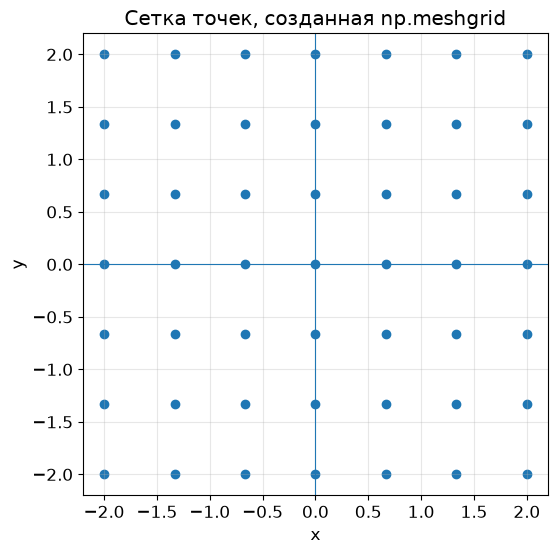

X.shape = (7, 7)
Y.shape = (7, 7)


In [8]:
x = np.linspace(-2, 2, 7)
y = np.linspace(-2, 2, 7)

X, Y = np.meshgrid(x, y)

plt.figure(figsize=(6, 6))
plt.scatter(X, Y)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.grid(True, alpha=0.3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Сетка точек, созданная np.meshgrid")
plt.show()

print("X.shape =", X.shape)
print("Y.shape =", Y.shape)

### Мини-задание

Если:

```python
x = np.linspace(-3, 3, 9)
y = np.linspace(-2, 2, 5)
X, Y = np.meshgrid(x, y)
```

какой будет форма `X` и `Y`?

<details>
<summary><b>Ответ</b></summary>

```text
X.shape = (5, 9)
Y.shape = (5, 9)
```

Первая размерность определяется количеством значений `y`, вторая — количеством значений `x`.

</details>

# 6. Поверхности второго порядка

## Эллипсоид

$$
\frac{x^2}{a^2}+\frac{y^2}{b^2}+\frac{z^2}{c^2}=1.
$$

Параметризация:

$$
x=a\sin u\cos v,
$$

$$
y=b\sin u\sin v,
$$

$$
z=c\cos u,
$$

$$
u\in[0,\pi],\qquad v\in[0,2\pi].
$$

## Однополостный гиперболоид

$$
\frac{x^2}{a^2}+\frac{y^2}{b^2}-\frac{z^2}{c^2}=1.
$$

Удобная параметризация:

$$
x=a\cosh u\cos v,\quad
y=b\cosh u\sin v,\quad
z=c\sinh u.
$$

## Эллиптический параболоид

$$
z=\frac{x^2}{a^2}+\frac{y^2}{b^2}.
$$

Его удобно строить непосредственно по сетке $X,Y$.

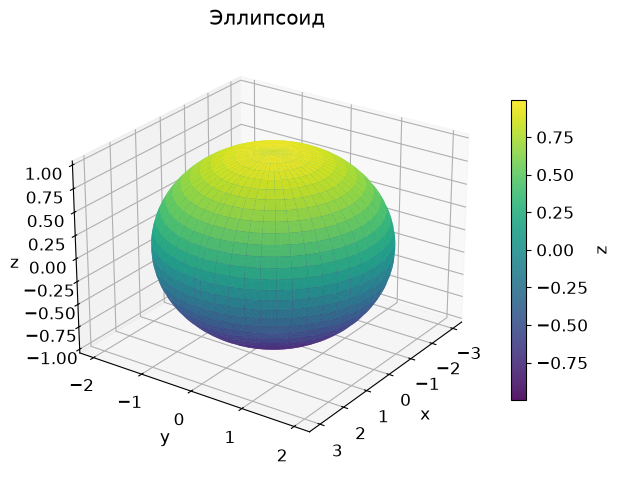

In [9]:
# Эллипсоид a=3, b=2, c=1.

a, b, c = 3.0, 2.0, 1.0

u = np.linspace(0, np.pi, 60)
v = np.linspace(0, 2*np.pi, 100)
U, V = np.meshgrid(u, v)

X = a*np.sin(U)*np.cos(V)
Y = b*np.sin(U)*np.sin(V)
Z = c*np.cos(U)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.9)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Эллипсоид")
ax.view_init(elev=25, azim=35)
plt.colorbar(surf, ax=ax, shrink=0.65, label="z")
plt.show()

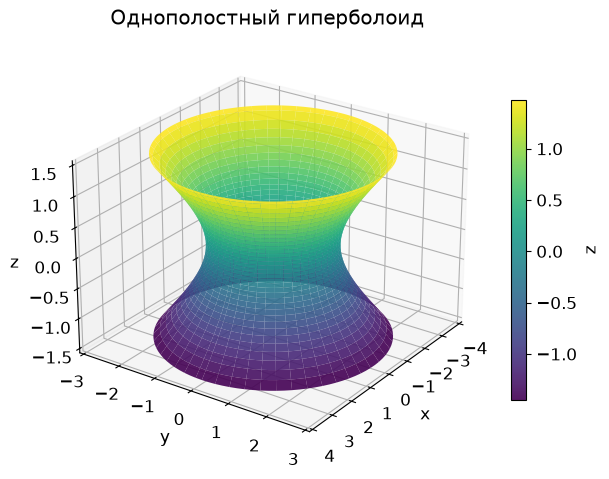

In [10]:
# Однополостный гиперболоид.

u = np.linspace(-1.2, 1.2, 70)
v = np.linspace(0, 2*np.pi, 100)
U, V = np.meshgrid(u, v)

X = 2*np.cosh(U)*np.cos(V)
Y = 1.5*np.cosh(U)*np.sin(V)
Z = np.sinh(U)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.9)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Однополостный гиперболоид")
ax.view_init(elev=25, azim=35)
plt.colorbar(surf, ax=ax, shrink=0.65, label="z")
plt.show()

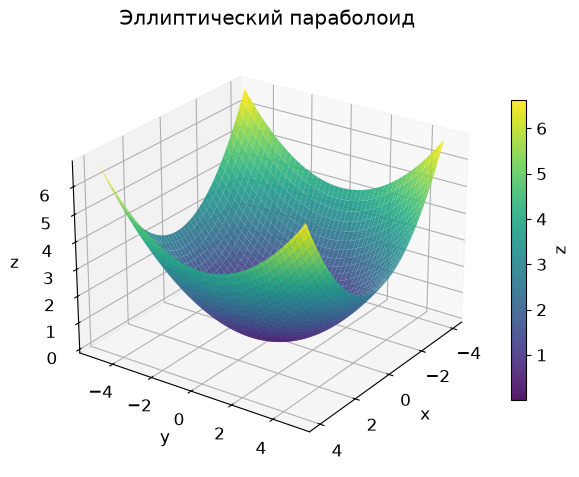

In [11]:
# Эллиптический параболоид z = x^2/4 + y^2/9.

x = np.linspace(-4, 4, 90)
y = np.linspace(-5, 5, 90)
X, Y = np.meshgrid(x, y)
Z = X**2/4 + Y**2/9

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.9)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Эллиптический параболоид")
ax.view_init(elev=25, azim=35)
plt.colorbar(surf, ax=ax, shrink=0.65, label="z")
plt.show()

## Интерактивный обзор поверхности

В Matplotlib камера задаётся через:

```python
ax.view_init(elev, azim)
```

- `elev` — высота камеры;
- `azim` — поворот вокруг объекта.

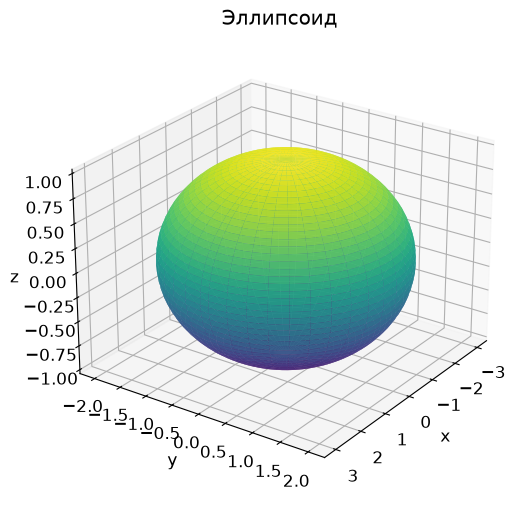

In [12]:
def show_surface(surface="Эллипсоид", elev=25, azim=35):
    fig = plt.figure(figsize=(7, 6))
    ax = fig.add_subplot(111, projection="3d")

    if surface == "Эллипсоид":
        u = np.linspace(0, np.pi, 50)
        v = np.linspace(0, 2*np.pi, 80)
        U, V = np.meshgrid(u, v)
        X = 3*np.sin(U)*np.cos(V)
        Y = 2*np.sin(U)*np.sin(V)
        Z = np.cos(U)

    elif surface == "Гиперболоид":
        u = np.linspace(-1.1, 1.1, 50)
        v = np.linspace(0, 2*np.pi, 80)
        U, V = np.meshgrid(u, v)
        X = 2*np.cosh(U)*np.cos(V)
        Y = 1.5*np.cosh(U)*np.sin(V)
        Z = np.sinh(U)

    else:
        x = np.linspace(-4, 4, 70)
        y = np.linspace(-5, 5, 70)
        X, Y = np.meshgrid(x, y)
        Z = X**2/4 + Y**2/9

    ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.9)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_title(surface)
    ax.view_init(elev=elev, azim=azim)
    plt.show()

if WIDGETS_AVAILABLE:
    interact(
        show_surface,
        surface=Dropdown(
            options=["Эллипсоид", "Гиперболоид", "Параболоид"],
            value="Эллипсоид",
            description="Поверхность"
        ),
        elev=IntSlider(min=0, max=80, step=5, value=25, description="elev"),
        azim=IntSlider(min=-180, max=180, step=10, value=35, description="azim")
    );
else:
    show_surface()

## Задание 5

Для эллипсоида

$$
x=3\sin u\cos v,\qquad
y=2\sin u\sin v,\qquad
z=\cos u
$$

найдите точку при

$$
u=\frac{\pi}{2},\qquad v=0.
$$

Почему при фиксированном $u=\pi/2$ изменение $v$ ведёт точку по «экватору» эллипсоида?

<details>
<summary><b>Решение задания 5</b></summary>

При $u=\pi/2$:

$$
\sin u=1,\qquad \cos u=0.
$$

При $v=0$:

$$
\cos v=1,\qquad \sin v=0.
$$

Поэтому:

$$
(x,y,z)=(3,0,0).
$$

Если оставить $u=\pi/2$, то $z=0$, а

$$
x=3\cos v,\qquad y=2\sin v.
$$

Это эллипс в плоскости $z=0$ — «экватор» эллипсоида.

</details>

# 7. Линии уровня и 3D-поверхность

В ЛР требуется сравнить две визуализации функции

$$
f(x,y)=e^{-x^2-y^2}.
$$

В 3D это колоколообразная поверхность.

Линия уровня — множество точек, где

$$
f(x,y)=C.
$$

`contour` показывает поверхность как набор горизонтальных сечений, подобно топографической карте.

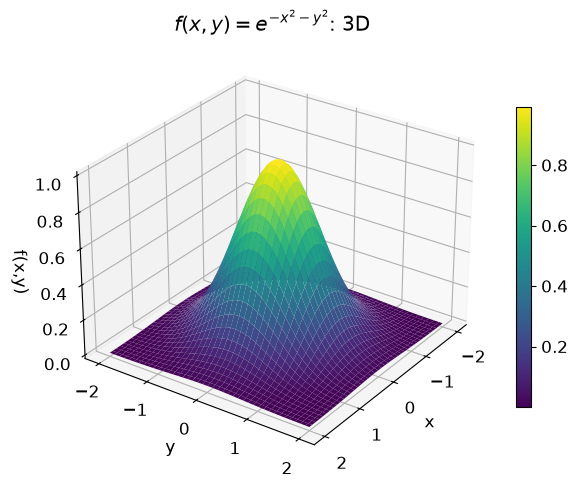

In [13]:
x = np.linspace(-2, 2, 160)
y = np.linspace(-2, 2, 160)
X, Y = np.meshgrid(x, y)
Z = np.exp(-X**2 - Y**2)

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(X, Y, Z, cmap="viridis")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("f(x,y)")
ax.set_title(r"$f(x,y)=e^{-x^2-y^2}$: 3D")
ax.view_init(elev=28, azim=35)
plt.colorbar(surf, ax=ax, shrink=0.65)
plt.show()

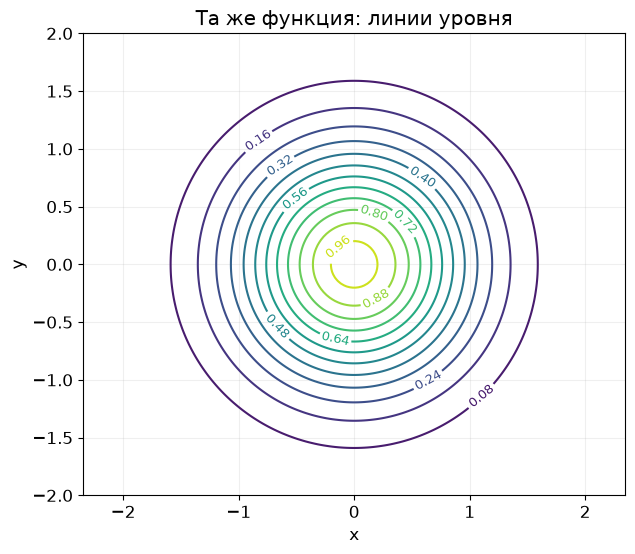

In [14]:
plt.figure(figsize=(7, 6))
cs = plt.contour(X, Y, Z, levels=12)
plt.clabel(cs, inline=True, fontsize=9)
plt.axis("equal")
plt.grid(True, alpha=0.2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Та же функция: линии уровня")
plt.show()

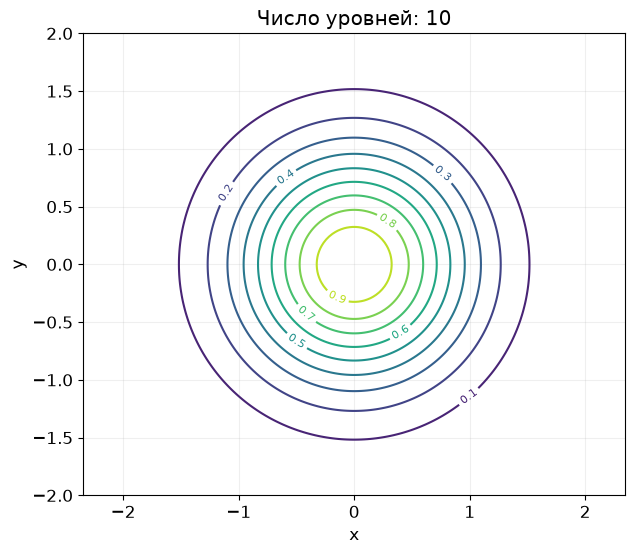

In [15]:
def show_contours(levels=10):
    plt.figure(figsize=(7, 6))
    cs = plt.contour(X, Y, Z, levels=levels)
    plt.clabel(cs, inline=True, fontsize=8)
    plt.axis("equal")
    plt.grid(True, alpha=0.2)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Число уровней: {levels}")
    plt.show()

if WIDGETS_AVAILABLE:
    interact(
        show_contours,
        levels=IntSlider(min=4, max=25, step=1, value=10, description="levels")
    );
else:
    show_contours()

## Задание 6

Для

$$
f(x,y)=e^{-x^2-y^2}
$$

ответьте:

1. где находится максимум;
2. почему линии уровня являются окружностями;
3. что означает более плотное расположение соседних линий.

<details>
<summary><b>Решение задания 6</b></summary>

Максимум:

$$
f(0,0)=1.
$$

Для линии уровня:

$$
e^{-x^2-y^2}=C.
$$

Логарифмируем:

$$
x^2+y^2=-\ln C.
$$

Это окружность.

Чем плотнее соседние линии уровня, тем быстрее меняется значение функции при небольшом перемещении, то есть тем круче поверхность.

</details>

# 8. Оформление графиков в ЛР

В методичке требуется сохранять графики в PDF или PNG с разрешением не менее 300 dpi.

PNG:

```python
plt.savefig(
    "figure.png",
    dpi=300,
    bbox_inches="tight"
)
```

PDF:

```python
plt.savefig(
    "figure.pdf",
    bbox_inches="tight"
)
```

На графиках должны быть:

- подписи осей;
- заголовок;
- легенда, если объектов несколько;
- сетка там, где она улучшает чтение;
- разумные границы осей;
- для 2D-кривых часто нужен `plt.axis("equal")`.

Последнее важно: при неодинаковом масштабе по осям даже окружность может выглядеть как эллипс.

# 9. Связь семинара с ЛР №4

| Пункт лабораторной | Что должно быть понятно |
|---|---|
| Эллипс, гипербола, парабола | параметризация и диапазон параметра |
| Матрицы преобразований | однородные координаты |
| Поворот + перенос | правая матрица действует первой |
| Общее уравнение | дискриминант и геометрический смысл коэффициентов |
| Эллипсоид | параметрическая сетка $(u,v)$ |
| Параболоид | `meshgrid` по $x,y$ |
| Гиперболоид | параметризация через $\cosh$ и $\sinh$ |
| `contour` | линии уровня той же функции |
| Сохранение | подписи, масштаб, 300 dpi, PNG/PDF |

## Мини-шпаргалка

### Семейство кривой

$$
\Delta=B^2-4AC.
$$

### Последовательность преобразований

Если сначала действует $M_1$, затем $M_2$:

$$
p_{\text{new}}=M_2M_1p.
$$

### Явная поверхность

```python
X, Y = np.meshgrid(x, y)
Z = f(X, Y)
```

### Параметрическая поверхность

```python
U, V = np.meshgrid(u, v)

X = X(U, V)
Y = Y(U, V)
Z = Z(U, V)
```

# 10. Вопросы для обсуждения

1. Почему эллипс удобно строить параметрически?
2. Почему у гиперболы нужно учитывать две ветви?
3. Что показывает знак $B^2-4AC$?
4. Что обычно означает наличие члена $xy$?
5. Зачем нужны однородные координаты?
6. Почему $TR$ и $RT$ дают разные результаты?
7. Какая матрица в произведении действует первой?
8. Для чего используется `np.meshgrid`?
9. Чем параметрическая поверхность отличается от явной $z=f(x,y)$?
10. Что такое линия уровня?
11. Почему `axis("equal")` важен для геометрических кривых?
12. Как изменить угол обзора 3D-графика?